Epoch 1/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.6446 - val_loss: 0.5916
Epoch 2/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.4190 - val_loss: 0.3637
Epoch 3/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2622 - val_loss: 0.2496
Epoch 4/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2020 - val_loss: 0.2166
Epoch 5/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1840 - val_loss: 0.2037
Epoch 6/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1752 - val_loss: 0.1927
Epoch 7/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1677 - val_loss: 0.1851
Epoch 8/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1638 - val_loss: 0.1821
Epoch 9/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1591 - val_loss: 0.1763
Epoch 10/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1528 - val_loss: 0.1671
Epoch 11/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1466 - val_loss: 0.1617
Epoch 12/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1415 - val_l

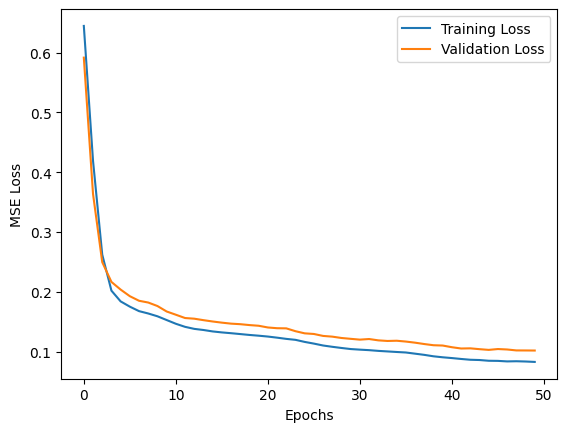

In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, confusion_matrix
from tensorflow.keras import layers, models

# 1. Load ECG dataset
df = pd.read_csv(
    'https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv',
    header=None
)

# 2. Separate features and labels
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

# 3. Normalize data
scaler = StandardScaler()
X = scaler.fit_transform(X)

# 4. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Use only normal ECG signals for training
X_normal = X_train[y_train == 1]

# 5. Create Encoder
encoder = models.Sequential([
    layers.Input(shape=(X.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu')
])

# 6. Create Decoder
decoder = models.Sequential([
    layers.Input(shape=(8,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(X.shape[1], activation='linear')
])

# 7. Create Autoencoder
autoencoder = models.Sequential([encoder, decoder])

autoencoder.compile(optimizer='adam', loss='mse')

# 8. Train model
history = autoencoder.fit(
    X_normal, X_normal,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# 9. Calculate reconstruction error
predictions = autoencoder.predict(X_test)
mse = np.mean(np.square(X_test - predictions), axis=1)

# 10. Find optimal threshold using F1-score
thresholds = np.linspace(mse.min(), mse.max(), 100)
best_f1 = 0

for t in thresholds:
    y_pred = np.where(mse > t, 0, 1)
    score = f1_score(y_test, y_pred, pos_label=0)

    if score > best_f1:
        best_f1 = score
        best_threshold = t

# 11. Detect anomalies
y_pred = np.where(mse > best_threshold, 0, 1)

print("Optimal Threshold:", best_threshold)
print("Best F1 Score:", best_f1)
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# 12. Plot training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()
